# 01 · Explore

First look at the 2015/16 shot data: how many shots, how often they go in, and where Leicester shot from.

Run `python src/download.py && python src/build_db.py` first.

In [1]:
import duckdb
import matplotlib.pyplot as plt
from mplsoccer import VerticalPitch

con = duckdb.connect("../data/leicester_xg.duckdb", read_only=True)
LEICESTER_BLUE = "#003090"
GRAY = "#9a9a9a"

Matplotlib is building the font cache; this may take a moment.


## Shots and goal rate by league

Non-penalty shots only. Bundesliga coverage is Leverkusen's 34 matches only.

In [2]:
con.sql('''
    SELECT competition,
           count(DISTINCT match_id)              AS matches,
           count(*)                              AS shots,
           round(count(*) / count(DISTINCT match_id), 1) AS shots_per_match,
           sum(is_goal)                          AS goals,
           round(avg(is_goal), 3)                AS goal_rate
    FROM np_shots
    GROUP BY competition
    ORDER BY competition
''').df()

,competition,matches,shots,shots_per_match,goals,goal_rate
0,England - Premier League,380,9817,25.8,914.0,0.093
1,France - Ligue 1,377,8723,23.1,852.0,0.098
2,Germany - 1. Bundesliga,34,830,24.4,82.0,0.099
3,Italy - Serie A,380,9877,26.0,858.0,0.087
4,Spain - La Liga,380,9071,23.9,945.0,0.104


## Penalties (kept out of the model)

In [3]:
con.sql('''
    SELECT count(*) AS penalties, sum(is_goal) AS scored, round(avg(is_goal), 3) AS conversion
    FROM shots WHERE is_penalty
''').df()

,penalties,scored,conversion
0,410,308.0,0.751


## Goal rate by distance

Sanity check: closer shots should go in far more often. Distance here is a rough version of the Week 2 feature.

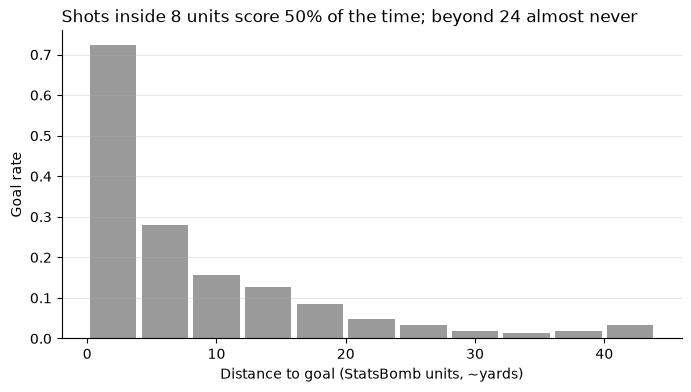

In [4]:
by_dist = con.sql('''
    SELECT floor(sqrt(power(120 - x, 2) + power(40 - y, 2)) / 4) * 4 AS distance,
           count(*) AS shots,
           avg(is_goal) AS goal_rate
    FROM np_shots
    GROUP BY 1
    HAVING count(*) >= 100
    ORDER BY 1
''').df()

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(by_dist.distance + 2, by_dist.goal_rate, width=3.6, color=GRAY)
ax.set_xlabel("Distance to goal (StatsBomb units, ~yards)")
ax.set_ylabel("Goal rate")
ax.set_title(f"Shots inside 8 units score {by_dist.goal_rate.iloc[:2].mean():.0%} of the time; beyond 24 almost never", loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
plt.show()

## Leicester's shots

Dot size is StatsBomb xG (benchmark only, our own model replaces it in Week 3). Filled blue = goal.

512 shots, 57 goals, 56.1 StatsBomb xG


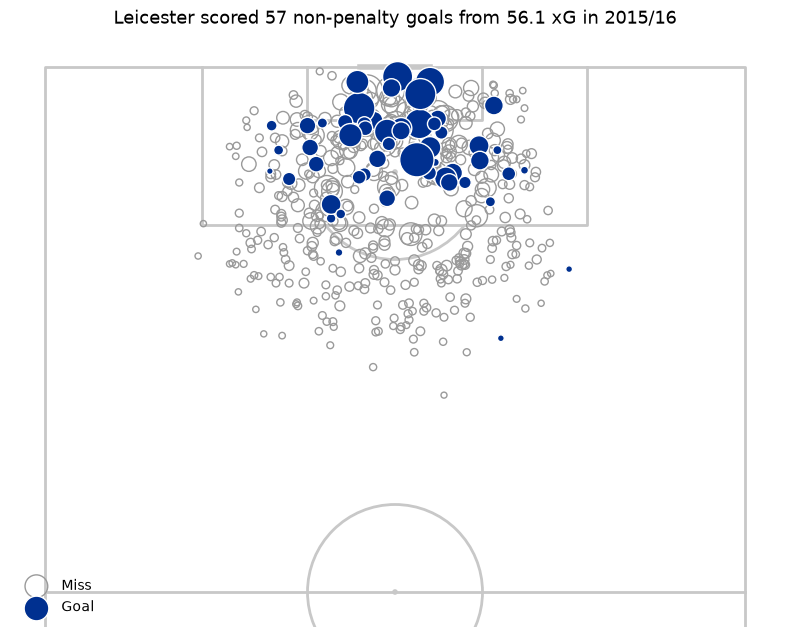

In [5]:
lei = con.sql("SELECT * FROM np_shots WHERE team = 'Leicester City'").df()
print(f"{len(lei)} shots, {lei.is_goal.sum()} goals, {lei.statsbomb_xg.sum():.1f} StatsBomb xG")

goals, misses = lei[lei.is_goal == 1], lei[lei.is_goal == 0]
pitch = VerticalPitch(half=True, pitch_type="statsbomb", line_color="#c8c8c8")
fig, ax = pitch.draw(figsize=(8, 7))
pitch.scatter(misses.x, misses.y, s=misses.statsbomb_xg * 600 + 15, ax=ax,
              facecolors="none", edgecolors=GRAY, linewidth=1, label="Miss")
pitch.scatter(goals.x, goals.y, s=goals.statsbomb_xg * 600 + 15, ax=ax,
              color=LEICESTER_BLUE, edgecolors="white", linewidth=1, label="Goal")
ax.legend(loc="lower left", frameon=False)
ax.set_title(f"Leicester scored {lei.is_goal.sum()} non-penalty goals from {lei.statsbomb_xg.sum():.1f} xG in 2015/16",
             fontsize=13)
fig.savefig("../figures/leicester_shot_map_explore.png", dpi=150, bbox_inches="tight")
plt.show()

## Leicester vs the rest of the Premier League

Quick preview of the Week 4 question: volume vs quality.

In [6]:
pl = con.sql('''
    SELECT team,
           count(*) / count(DISTINCT match_id) AS shots_per_match,
           avg(statsbomb_xg)                   AS xg_per_shot,
           sum(is_goal) - sum(statsbomb_xg)    AS goals_minus_xg
    FROM np_shots
    WHERE competition = 'England - Premier League'
    GROUP BY team
    ORDER BY shots_per_match DESC
''').df()
pl.round(3)

,team,shots_per_match,xg_per_shot,goals_minus_xg
0,Tottenham Hotspur,17.132,0.090,4.561
1,Liverpool,16.658,0.090,3.193
2,Manchester City,15.947,0.096,7.713
3,Arsenal,15.289,0.109,-2.521
4,West Ham United,14.605,0.093,8.607
5,Chelsea,13.947,0.094,1.338
6,Southampton,13.763,0.098,2.911
7,Leicester City,13.474,0.110,0.903
8,Everton,12.974,0.095,5.303
9,AFC Bournemouth,12.474,0.079,2.782


## Notes for Week 2

- `first_time`, `under_pressure` and `open_goal` are null when false in the raw data; `01_shots.sql` fills them with `false`.
- Every non-penalty shot has a freeze frame, so freeze frame features won't need missing-value handling.
- Bundesliga is Leverkusen-only; Ligue 1 is missing 3 matches.